In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("car_evaluation.csv")

print(df.head())
print(df.shape)
print(df.columns)
print(df.head())
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

   vhigh vhigh.1  2 2.1  small   low  unacc
0  vhigh   vhigh  2   2  small   med  unacc
1  vhigh   vhigh  2   2  small  high  unacc
2  vhigh   vhigh  2   2    med   low  unacc
3  vhigh   vhigh  2   2    med   med  unacc
4  vhigh   vhigh  2   2    med  high  unacc
(1727, 7)
Index(['vhigh', 'vhigh.1', '2', '2.1', 'small', 'low', 'unacc'], dtype='object')
   vhigh vhigh.1  2 2.1  small   low  unacc
0  vhigh   vhigh  2   2  small   med  unacc
1  vhigh   vhigh  2   2  small  high  unacc
2  vhigh   vhigh  2   2    med   low  unacc
3  vhigh   vhigh  2   2    med   med  unacc
4  vhigh   vhigh  2   2    med  high  unacc
Dataset Shape: (1727, 7)

Columns:
Index(['vhigh', 'vhigh.1', '2', '2.1', 'small', 'low', 'unacc'], dtype='object')

Missing Values:
vhigh      0
vhigh.1    0
2          0
2.1        0
small      0
low        0
unacc      0
dtype: int64


In [3]:
df.columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

print(df.head())

  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    med  unacc
1  vhigh  vhigh     2       2    small   high  unacc
2  vhigh  vhigh     2       2      med    low  unacc
3  vhigh  vhigh     2       2      med    med  unacc
4  vhigh  vhigh     2       2      med   high  unacc


In [4]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
  buying  maint doors persons lug_boot safety
0  vhigh  vhigh     2       2    small    med
1  vhigh  vhigh     2       2    small   high
2  vhigh  vhigh     2       2      med    low
3  vhigh  vhigh     2       2      med    med
4  vhigh  vhigh     2       2      med   high

Target:
0    unacc
1    unacc
2    unacc
3    unacc
4    unacc
Name: class, dtype: object


In [5]:
encoder = LabelEncoder()

for column in X.columns:
    X[column] = encoder.fit_transform(X[column])

y = encoder.fit_transform(y)

print(X.head())
print(y[:10])

   buying  maint  doors  persons  lug_boot  safety
0       3      3      0        0         2       2
1       3      3      0        0         2       0
2       3      3      0        0         1       1
3       3      3      0        0         1       2
4       3      3      0        0         1       0
[2 2 2 2 2 2 2 2 2 2]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1381, 6)
Testing Data: (346, 6)


In [7]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [8]:
y_pred = rf.predict(X_test)

print("Predicted Values:")
print(y_pred[:20])

print("\nActual Values:")
print(y_test[:20])

Predicted Values:
[1 2 2 2 0 2 2 0 2 2 2 2 2 2 3 2 0 2 2 2]

Actual Values:
[1 2 2 2 0 2 2 0 2 2 2 2 2 2 3 2 0 2 2 2]


In [14]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.9826589595375722
Accuracy Percentage: 98.26589595375722 %
Confusion Matrix:
[[ 75   0   2   0]
 [  1  13   0   0]
 [  2   0 240   0]
 [  1   0   0  12]]


In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96        77
           1       1.00      0.93      0.96        14
           2       0.99      0.99      0.99       242
           3       1.00      0.92      0.96        13

    accuracy                           0.98       346
   macro avg       0.99      0.95      0.97       346
weighted avg       0.98      0.98      0.98       346



In [13]:
importance = rf.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

    Feature  Importance
5    safety    0.273059
3   persons    0.223049
0    buying    0.184460
1     maint    0.163027
4  lug_boot    0.088880
2     doors    0.067525


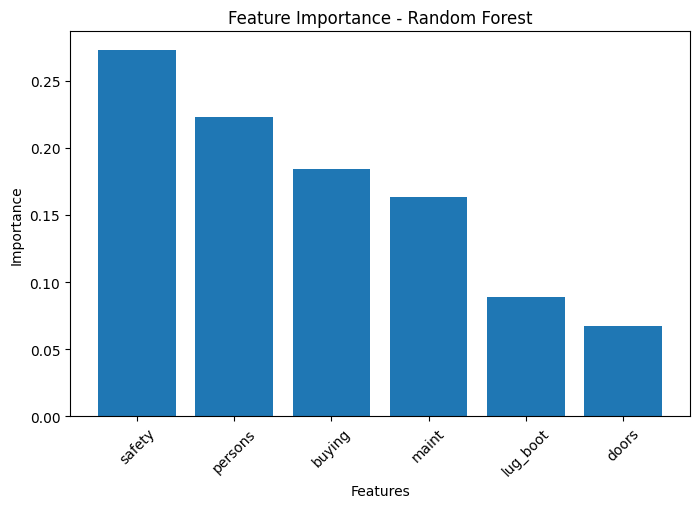

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance - Random Forest")

plt.xticks(rotation=45)

plt.show()